# 1-loyiha
Python va Jupyter muhitida dastlabki model

Scikit-learn tarkibidagi haqiqiy WDBC ochiq ma’lumotlari. 1 = malignant, 0 = benign. Bu diabet dataseti emas.


In [1]:
# Python va Jupyter muhitida dastlabki model
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

from importlib.metadata import version
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay

def main():
    versions = {p: version(p) for p in
                ["numpy", "pandas", "matplotlib", "scikit-learn"]}
    save_json("environment.json", versions)
    dataset = load_breast_cancer(as_frame=True)
    X = dataset.data
    y = (dataset.target == 0).astype(int)
    frame = X.assign(malignant=y)
    frame.to_csv(DATA / "breast_cancer.csv", index=False)
    train, test = train_test_split(np.arange(len(y)),
        test_size=0.2, random_state=SEED, stratify=y)
    assert not set(train) & set(test)
    model = make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=3000, random_state=SEED))
    model.fit(X.iloc[train], y.iloc[train])
    probability = model.predict_proba(X.iloc[test])[:, 1]
    result = binary_metrics(y.iloc[test], probability)
    result["positive_class"] = "malignant"
    save_json("metrics.json", result)
    pd.DataFrame({"row_id": test, "y_true": y.iloc[test],
        "p_malignant": probability}).to_csv(
        OUT / "predictions.csv", index=False)
    ConfusionMatrixDisplay.from_predictions(y.iloc[test],
        probability >= 0.5, labels=[0, 1])
    plt.title("WDBC: test, 1 = malignant")
    save_plot("confusion_matrix.png")
    RocCurveDisplay.from_predictions(y.iloc[test], probability)
    save_plot("roc.png")
    joblib.dump(model, OUT / "model.joblib")
    save_json("split.json", {"train": train.tolist(),
                             "test": test.tolist()})
    print(json.dumps(result, indent=2))

if __name__ == "__main__":
    main()


{
  "n": 114,
  "threshold": 0.5,
  "accuracy": 0.9649122807017544,
  "precision": 0.975,
  "recall": 0.9285714285714286,
  "specificity": 0.9861111111111112,
  "f1": 0.9512195121951219,
  "roc_auc": 0.996031746031746,
  "brier": 0.02131313900119227,
  "tn": 71,
  "fp": 1,
  "fn": 3,
  "tp": 39,
  "positive_class": "malignant"
}


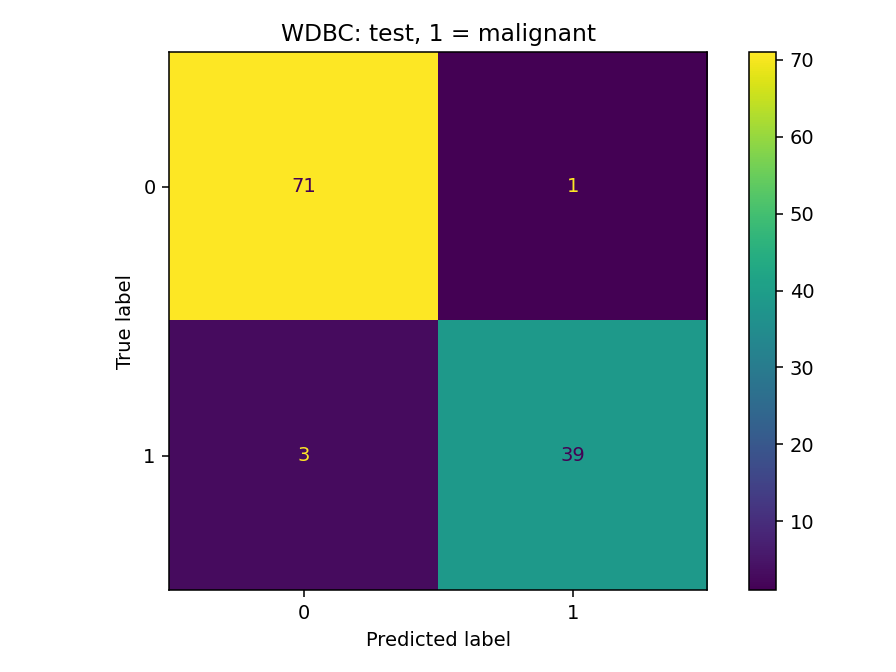

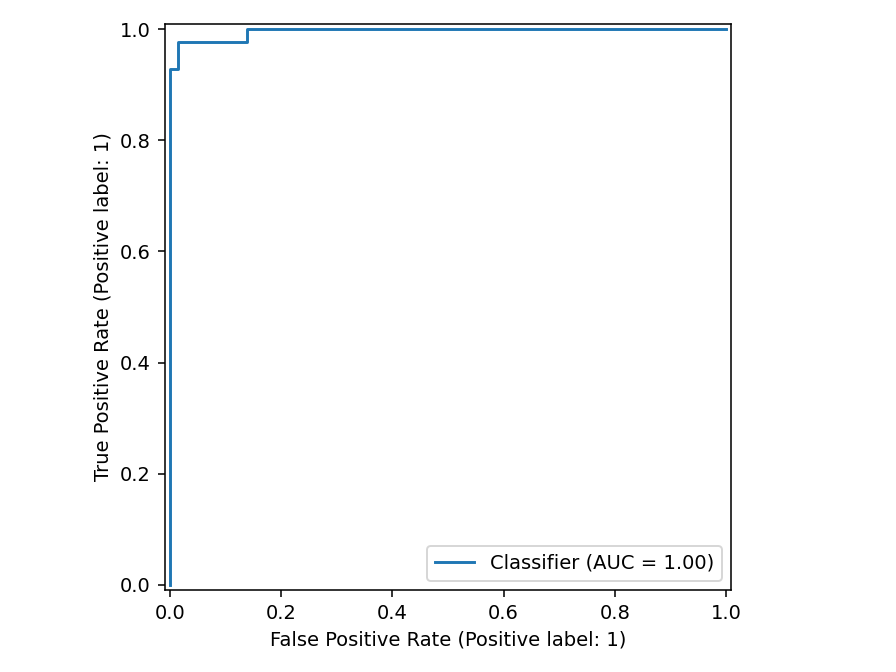

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
